In [2]:
# Gabungan modul simulator ILP (RAW, WAR, WAW). Sumber modular: lihat folder ilp/
# ===== ilp/models.py =====
"""Model data & skenario instruksi (anggota 1)."""
from dataclasses import dataclass, field


@dataclass
class Instruction:
    name: str
    destination: str
    sources: list = field(default_factory=list)

    def __str__(self):
        return f"{self.name}: {self.destination} = {' + '.join(self.sources)}"


@dataclass
class Dependency:
    src: str   # instruksi lebih awal (urutan program)
    dst: str   # instruksi lebih akhir
    kind: str  # "RAW" | "WAR" | "WAW"
    reg: str   # register penyebab dependensi


# Satu skenario murni per jenis hazard + satu skenario campuran
SCENARIOS = {
    "RAW": [
        Instruction("I1", "R1", ["R2", "R3"]),
        Instruction("I2", "R4", ["R5", "R6"]),
        Instruction("I3", "R7", ["R1", "R4"]),
        Instruction("I4", "R8", ["R9", "R10"]),
        Instruction("I5", "R11", ["R7", "R8"]),
        Instruction("I6", "R12", ["R13", "R14"]),
    ],
    "WAR": [
        Instruction("I1", "R4", ["R1", "R2"]),
        Instruction("I2", "R1", ["R5", "R6"]),    # tulis R1 yang dibaca I1
        Instruction("I3", "R7", ["R2", "R3"]),
        Instruction("I4", "R2", ["R8", "R9"]),    # tulis R2 yang dibaca I1 & I3
        Instruction("I5", "R10", ["R11", "R12"]),
    ],
    "WAW": [
        Instruction("I1", "R1", ["R2", "R3"]),
        Instruction("I2", "R1", ["R4", "R5"]),    # tulis ulang R1
        Instruction("I3", "R6", ["R7", "R8"]),
        Instruction("I4", "R1", ["R9", "R10"]),   # tulis ulang R1 lagi
        Instruction("I5", "R6", ["R11", "R12"]),  # tulis ulang R6
    ],
    "MIXED": [
        Instruction("I1", "R1", ["R2", "R3"]),
        Instruction("I2", "R4", ["R1", "R5"]),
        Instruction("I3", "R2", ["R6", "R7"]),
        Instruction("I4", "R1", ["R8", "R9"]),
        Instruction("I5", "R10", ["R4", "R1"]),
        Instruction("I6", "R11", ["R12", "R13"]),
    ],
}

SCENARIO_TITLES = {
    "RAW": "RAW (Read After Write) - True Dependency",
    "WAR": "WAR (Write After Read) - Anti Dependency",
    "WAW": "WAW (Write After Write) - Output Dependency",
    "MIXED": "Gabungan RAW + WAR + WAW",
}


# ===== ilp/dependencies.py =====
"""Deteksi dependensi RAW, WAR, WAW (anggota 2)."""


def detect_dependencies(instructions):
    """
    Mengembalikan list Dependency (src -> dst, src lebih awal di program).

    RAW: j MEMBACA register yang terakhir DITULIS i        (i.dest in j.sources)
    WAR: j MENULIS register yang sebelumnya DIBACA i       (j.dest in i.sources)
    WAW: j MENULIS register yang sebelumnya DITULIS i      (j.dest == i.dest)

    Pencarian mundur berhenti di penulis terdekat, sehingga tidak ada
    dependensi palsu yang melewati penulisan ulang register.
    """
    deps = []
    for j, inst in enumerate(instructions):
        # --- RAW: cari penulis terakhir untuk tiap source ---
        for reg in dict.fromkeys(inst.sources):
            for i in range(j - 1, -1, -1):
                if instructions[i].destination == reg:
                    deps.append(Dependency(instructions[i].name, inst.name, "RAW", reg))
                    break

        # --- WAR & WAW: lihat siapa yang memakai register tujuan sebelumnya ---
        reg = inst.destination
        for i in range(j - 1, -1, -1):
            prev = instructions[i]
            if prev.destination == reg:
                deps.append(Dependency(prev.name, inst.name, "WAW", reg))
                break  # penulis sebelumnya sudah menjadi batas
            if reg in prev.sources:
                deps.append(Dependency(prev.name, inst.name, "WAR", reg))
    return deps


def show_dependencies(instructions, deps):
    print("\n" + "=" * 50)
    print("DEPENDENCY ANALYSIS")
    print("=" * 50)
    if not deps:
        print("No dependencies found.")
        return
    for d in deps:
        print(f"{d.dst} depends on {d.src}  [{d.kind}] (Register: {d.reg})")


# ===== ilp/scheduler.py =====
"""Eksekusi sequential & ILP (anggota 3)."""


def sequential_execution(instructions, verbose=True):
    if verbose:
        print("\n" + "=" * 50)
        print("SEQUENTIAL EXECUTION")
        print("=" * 50)
        for c, inst in enumerate(instructions, 1):
            print(f"Cycle {c}: Executing {inst}")
        print(f"\nTotal Sequential Cycles: {len(instructions)}")
    return len(instructions)


def schedule(instructions, deps, renaming=False):
    """
    Penjadwalan ASAP: instruksi dijalankan di cycle setelah SEMUA
    dependensinya selesai.

    renaming=False : RAW, WAR, WAW semuanya menjadi batasan urutan.
    renaming=True  : WAR & WAW (name dependency) hilang karena register
                     di-rename; hanya RAW (true dependency) yang tersisa.
    """
    active = [d for d in deps if (not renaming or d.kind == "RAW")]
    cycle_of = {}
    for inst in instructions:  # urutan program sudah topologis
        preds = [cycle_of[d.src] for d in active if d.dst == inst.name]
        cycle_of[inst.name] = (max(preds) + 1) if preds else 1
    return cycle_of


def parallel_execution(instructions, deps, renaming=False, verbose=True):
    cycle_of = schedule(instructions, deps, renaming)
    total = max(cycle_of.values())
    if verbose:
        label = "DENGAN REGISTER RENAMING" if renaming else "TANPA RENAMING"
        print("\n" + "=" * 50)
        print(f"INSTRUCTION-LEVEL PARALLEL EXECUTION ({label})")
        print("=" * 50)
        for c in range(1, total + 1):
            print(f"\nCycle {c}:")
            for inst in instructions:
                if cycle_of[inst.name] == c:
                    print(f"  -> {inst}")
        print(f"\nTotal ILP Cycles: {total}")
    return total, cycle_of


# ===== ilp/graph.py =====
"""Dependency graph (anggota 4).

Utama: Graphviz (`dot`) -> layout rapi tanpa garis menembus node.
Cadangan: matplotlib jika `dot` tidak terpasang.
"""
import shutil
import subprocess
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

COLORS = {"RAW": "#d62728", "WAR": "#1f77b4", "WAW": "#2ca02c"}


def _layout(instructions, cycle_of):
    layers = {}
    for inst in instructions:
        layers.setdefault(cycle_of[inst.name], []).append(inst.name)
    pos = {}
    for lvl, names in layers.items():
        for k, n in enumerate(names):
            pos[n] = (lvl * 3.2, (len(names) - 1) / 2 * 1.9 - k * 1.9)
    return pos


def draw_graph_matplotlib(instructions, deps, cycle_of, title, path):
    pos = _layout(instructions, cycle_of)
    by_name = {i.name: i for i in instructions}
    xs = [p[0] for p in pos.values()]
    ys = [p[1] for p in pos.values()]

    fig, ax = plt.subplots(figsize=(max(7, (max(xs) - min(xs)) * 1.1 + 4), max(4.5, (max(ys) - min(ys)) * 0.9 + 3)))
    ax.set_title(title, fontsize=13, fontweight="bold")
    w, h = 2.3, 1.0

    for d in deps:
        (x1, y1), (x2, y2) = pos[d.src], pos[d.dst]
        skip = cycle_of[d.dst] - cycle_of[d.src] > 1
        rad = 0.0 if not skip else (0.35 if y1 >= y2 else -0.35)
        arrow = FancyArrowPatch(
            (x1 + w / 2, y1), (x2 - w / 2, y2), connectionstyle=f"arc3,rad={rad}",
            arrowstyle="-|>", mutation_scale=16, lw=2, color=COLORS[d.kind], zorder=1,
            shrinkA=0, shrinkB=2)
        ax.add_patch(arrow)
        mx, my = (x1 + x2) / 2, (y1 + y2) / 2 + rad * (x2 - x1) * -0.5
        ax.text(mx, my + 0.18, f"{d.kind} ({d.reg})", color=COLORS[d.kind], fontsize=8.5,
                ha="center", fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.9), zorder=3)

    for n, (x, y) in pos.items():
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.05",
                                    fc="#f4f4f4", ec="#333", lw=1.4, zorder=2))
        inst = by_name[n]
        ax.text(x, y + 0.2, n, ha="center", va="center", fontsize=11, fontweight="bold", zorder=4)
        ax.text(x, y - 0.2, f"{inst.destination} = {' + '.join(inst.sources)}",
                ha="center", va="center", fontsize=9, zorder=4)

    for lvl in sorted({cycle_of[n] for n in pos}):
        ax.text(lvl * 3.2, max(ys) + 1.4, f"Cycle {lvl}", ha="center", fontsize=10, color="#555")

    kinds_used = sorted({d.kind for d in deps})
    handles = [plt.Line2D([0], [0], color=COLORS[k], lw=3, label=k) for k in kinds_used]
    if handles:
        ax.legend(handles=handles, loc="lower right", title="Jenis dependensi")
    ax.set_xlim(min(xs) - 2, max(xs) + 2)
    ax.set_ylim(min(ys) - 1.5, max(ys) + 2.2)
    ax.axis("off")
    fig.tight_layout()
    fig.savefig(path, dpi=160)
    plt.close(fig)


def to_dot(instructions, deps, cycle_of, title):
    """Bangun teks DOT; node sekelas (cycle sama) diberi rank=same."""
    lines = [
        "digraph G {",
        '  rankdir=LR; nodesep=0.6; ranksep=1.3; splines=true;',
        f'  labelloc=t; fontsize=18; fontname="Helvetica-Bold"; label="{title}";',
        '  node [shape=box, style="rounded,filled", fillcolor="#f4f4f4", fontname="Helvetica", fontsize=12];',
        '  edge [fontname="Helvetica-Bold", fontsize=11, penwidth=2];',
    ]
    for inst in instructions:
        lbl = f"{inst.name}\\n{inst.destination} = {' + '.join(inst.sources)}"
        lines.append(f'  {inst.name} [label="{lbl}"];')
    for c in sorted(set(cycle_of.values())):
        names = " ".join(f"{n};" for n, v in cycle_of.items() if v == c)
        lines.append(f'  {{ rank=same; {names} }}')
    for d in deps:
        col = COLORS[d.kind]
        lines.append(f'  {d.src} -> {d.dst} [label="{d.kind} ({d.reg})", color="{col}", fontcolor="{col}"];')
    lines.append("}")
    return "\n".join(lines)


def draw_graph(instructions, deps, cycle_of, title, path):
    if shutil.which("dot"):
        dot_path = path.rsplit(".", 1)[0] + ".dot"
        with open(dot_path, "w") as f:
            f.write(to_dot(instructions, deps, cycle_of, title))
        subprocess.run(["dot", "-Tpng", "-Gdpi=160", dot_path, "-o", path], check=True)
    else:
        draw_graph_matplotlib(instructions, deps, cycle_of, title, path)


"""Program utama: jalankan simulator untuk RAW, WAR, WAW, dan MIXED."""
import os

OUT_DIR = "graphs"


def run(name):
    instructions = SCENARIOS[name]
    print("\n" + "*" * 60)
    print(f"  SKENARIO {SCENARIO_TITLES[name]}")
    print("*" * 60)
    print("\nInstruction Set:")
    for inst in instructions:
        print(inst)

    deps = detect_dependencies(instructions)
    show_dependencies(instructions, deps)

    seq = sequential_execution(instructions)
    ilp, cycle_of = parallel_execution(instructions, deps, renaming=False)
    ilp_rn, _ = parallel_execution(instructions, deps, renaming=True)

    os.makedirs(OUT_DIR, exist_ok=True)
    path = os.path.join(OUT_DIR, f"dependency_graph_{name.lower()}.png")
    draw_graph(instructions, deps, cycle_of, f"Dependency Graph - {SCENARIO_TITLES[name]}", path)

    print("\n" + "=" * 50)
    print("PERFORMANCE COMPARISON")
    print("=" * 50)
    print(f"Sequential Cycles        : {seq}")
    print(f"ILP Cycles (no renaming) : {ilp}   Speedup {seq / ilp:.2f}x  IPC {len(instructions) / ilp:.2f}")
    print(f"ILP Cycles (renaming)    : {ilp_rn}   Speedup {seq / ilp_rn:.2f}x  IPC {len(instructions) / ilp_rn:.2f}")
    print(f"Graph disimpan di        : {path}")
    return dict(name=name, instructions=instructions, deps=deps, seq=seq, ilp=ilp, ilp_rn=ilp_rn, graph=path)


if __name__ == "__main__":
    for s in SCENARIOS:
        run(s)



************************************************************
  SKENARIO RAW (Read After Write) - True Dependency
************************************************************

Instruction Set:
I1: R1 = R2 + R3
I2: R4 = R5 + R6
I3: R7 = R1 + R4
I4: R8 = R9 + R10
I5: R11 = R7 + R8
I6: R12 = R13 + R14

DEPENDENCY ANALYSIS
I3 depends on I1  [RAW] (Register: R1)
I3 depends on I2  [RAW] (Register: R4)
I5 depends on I3  [RAW] (Register: R7)
I5 depends on I4  [RAW] (Register: R8)

SEQUENTIAL EXECUTION
Cycle 1: Executing I1: R1 = R2 + R3
Cycle 2: Executing I2: R4 = R5 + R6
Cycle 3: Executing I3: R7 = R1 + R4
Cycle 4: Executing I4: R8 = R9 + R10
Cycle 5: Executing I5: R11 = R7 + R8
Cycle 6: Executing I6: R12 = R13 + R14

Total Sequential Cycles: 6

INSTRUCTION-LEVEL PARALLEL EXECUTION (TANPA RENAMING)

Cycle 1:
  -> I1: R1 = R2 + R3
  -> I2: R4 = R5 + R6
  -> I4: R8 = R9 + R10
  -> I6: R12 = R13 + R14

Cycle 2:
  -> I3: R7 = R1 + R4

Cycle 3:
  -> I5: R11 = R7 + R8

Total ILP Cycles: 3

INSTRUCT

## Kasus Terpadu: RAW + WAR + WAW dalam Satu Program

Satu program berisi 6 instruksi yang memuat ketiga jenis hazard. Untuk **setiap implementasi** (RAW, WAR, WAW) dibuat dependency graph tersendiri, ditambah satu graph gabungan.

| Dependensi | Pasangan | Register | Penyebab |
|---|---|---|---|
| RAW | I1 -> I2 | R1 | I2 membaca R1 yang ditulis I1 |
| RAW | I2 -> I5 | R4 | I5 membaca R4 yang ditulis I2 |
| RAW | I4 -> I5 | R1 | I5 membaca R1 hasil tulis terakhir (I4) |
| WAR | I1 -> I3 | R2 | I3 menulis R2 yang dibaca I1 |
| WAR | I2 -> I4 | R1 | I4 menulis R1 yang dibaca I2 |
| WAW | I1 -> I4 | R1 | I4 menulis ulang R1 yang ditulis I1 |


In [3]:
# ===== Kasus terpadu =====
CASE = [
    Instruction("I1", "R1",  ["R2", "R3"]),    # tulis R1, baca R2
    Instruction("I2", "R4",  ["R1", "R5"]),    # RAW: baca R1 dari I1
    Instruction("I3", "R2",  ["R6", "R7"]),    # WAR: tulis R2 yang dibaca I1
    Instruction("I4", "R1",  ["R8", "R9"]),    # WAW: tulis ulang R1 (I1); WAR: R1 dibaca I2
    Instruction("I5", "R10", ["R4", "R1"]),    # RAW: R4 dari I2, R1 dari I4
    Instruction("I6", "R11", ["R12", "R13"]),  # independen
]
CASE_TITLE = "Kasus Terpadu RAW + WAR + WAW"

def schedule_only(instructions, deps, kinds):
    """Jadwal ASAP yang hanya memperhitungkan dependensi jenis `kinds`."""
    active = [d for d in deps if d.kind in kinds]
    cyc = {}
    for inst in instructions:
        preds = [cyc[d.src] for d in active if d.dst == inst.name]
        cyc[inst.name] = (max(preds) + 1) if preds else 1
    return active, cyc

def run_case(instructions=CASE, title=CASE_TITLE):
    print("Instruction Set:")
    for i in instructions: print(" ", i)

    deps = detect_dependencies(instructions)
    show_dependencies(instructions, deps)
    seq = sequential_execution(instructions)
    ilp, cyc_all = parallel_execution(instructions, deps, renaming=False)
    ilp_rn, _    = parallel_execution(instructions, deps, renaming=True)

    os.makedirs(OUT_DIR, exist_ok=True)
    paths = {}
    # Satu graph per implementasi hazard
    for kind, label in [("RAW", "RAW (True Dependency)"),
                        ("WAR", "WAR (Anti Dependency)"),
                        ("WAW", "WAW (Output Dependency)")]:
        active, cyc = schedule_only(instructions, deps, {kind})
        p = os.path.join(OUT_DIR, f"kasus_terpadu_{kind.lower()}.png")
        draw_graph(instructions, active, cyc, f"{title} - hanya {label}", p)
        paths[kind] = p
        print(f"[{kind}] {len(active)} dependensi -> {p}")
    # Graph gabungan
    p = os.path.join(OUT_DIR, "kasus_terpadu_gabungan.png")
    draw_graph(instructions, deps, cyc_all, f"{title} - Gabungan", p)
    paths["GABUNGAN"] = p

    print("\n" + "=" * 50); print("PERFORMANCE COMPARISON"); print("=" * 50)
    print(f"Sequential Cycles        : {seq}")
    print(f"ILP Cycles (no renaming) : {ilp}   Speedup {seq/ilp:.2f}x  IPC {len(instructions)/ilp:.2f}")
    print(f"ILP Cycles (renaming)    : {ilp_rn}   Speedup {seq/ilp_rn:.2f}x  IPC {len(instructions)/ilp_rn:.2f}")
    return deps, paths

deps_case, paths_case = run_case()


Instruction Set:
  I1: R1 = R2 + R3
  I2: R4 = R1 + R5
  I3: R2 = R6 + R7
  I4: R1 = R8 + R9
  I5: R10 = R4 + R1
  I6: R11 = R12 + R13

DEPENDENCY ANALYSIS
I2 depends on I1  [RAW] (Register: R1)
I3 depends on I1  [WAR] (Register: R2)
I4 depends on I2  [WAR] (Register: R1)
I4 depends on I1  [WAW] (Register: R1)
I5 depends on I2  [RAW] (Register: R4)
I5 depends on I4  [RAW] (Register: R1)

SEQUENTIAL EXECUTION
Cycle 1: Executing I1: R1 = R2 + R3
Cycle 2: Executing I2: R4 = R1 + R5
Cycle 3: Executing I3: R2 = R6 + R7
Cycle 4: Executing I4: R1 = R8 + R9
Cycle 5: Executing I5: R10 = R4 + R1
Cycle 6: Executing I6: R11 = R12 + R13

Total Sequential Cycles: 6

INSTRUCTION-LEVEL PARALLEL EXECUTION (TANPA RENAMING)

Cycle 1:
  -> I1: R1 = R2 + R3
  -> I6: R11 = R12 + R13

Cycle 2:
  -> I2: R4 = R1 + R5
  -> I3: R2 = R6 + R7

Cycle 3:
  -> I4: R1 = R8 + R9

Cycle 4:
  -> I5: R10 = R4 + R1

Total ILP Cycles: 4

INSTRUCTION-LEVEL PARALLEL EXECUTION (DENGAN REGISTER RENAMING)

Cycle 1:
  -> I1: R1 =

RAW


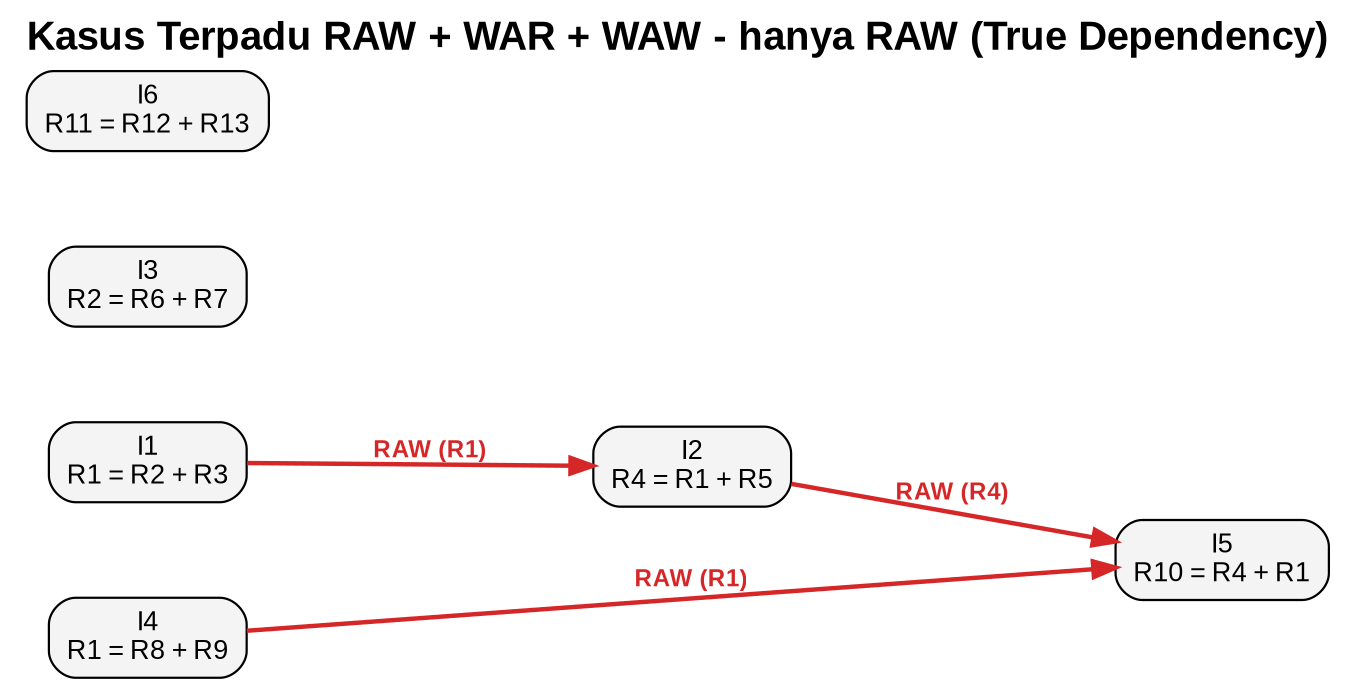

WAR


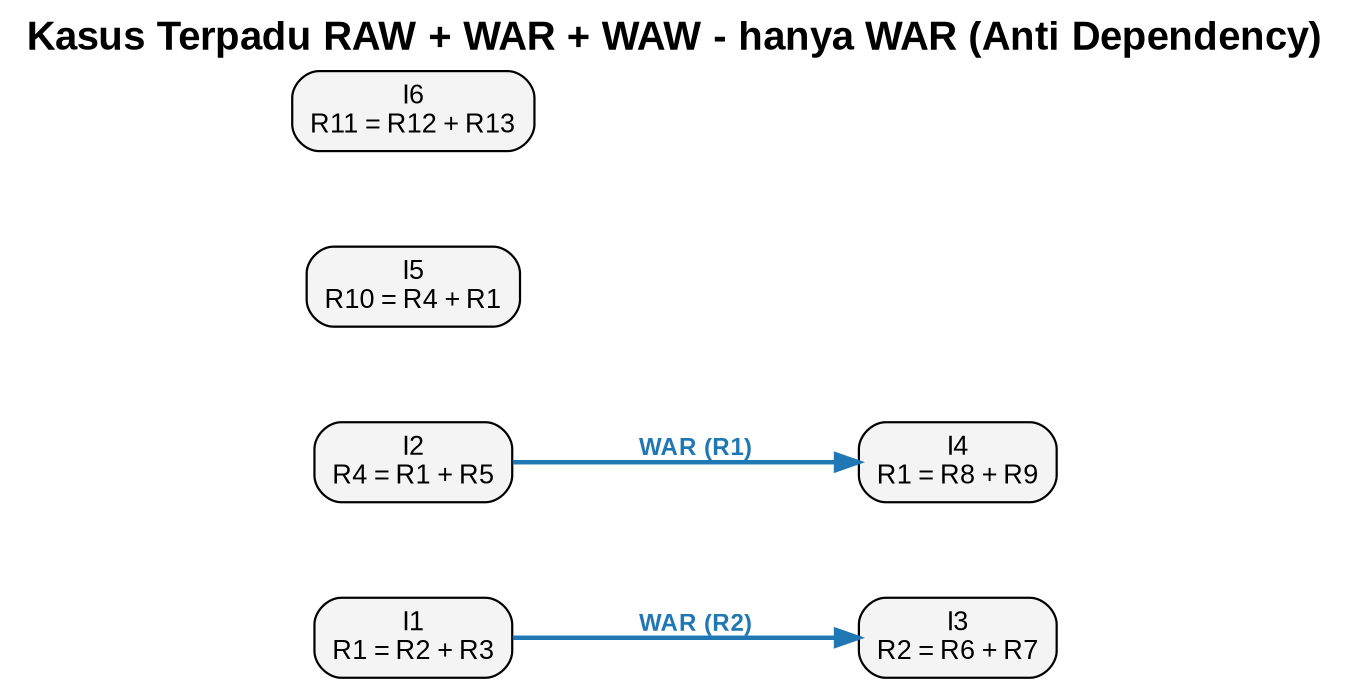

WAW


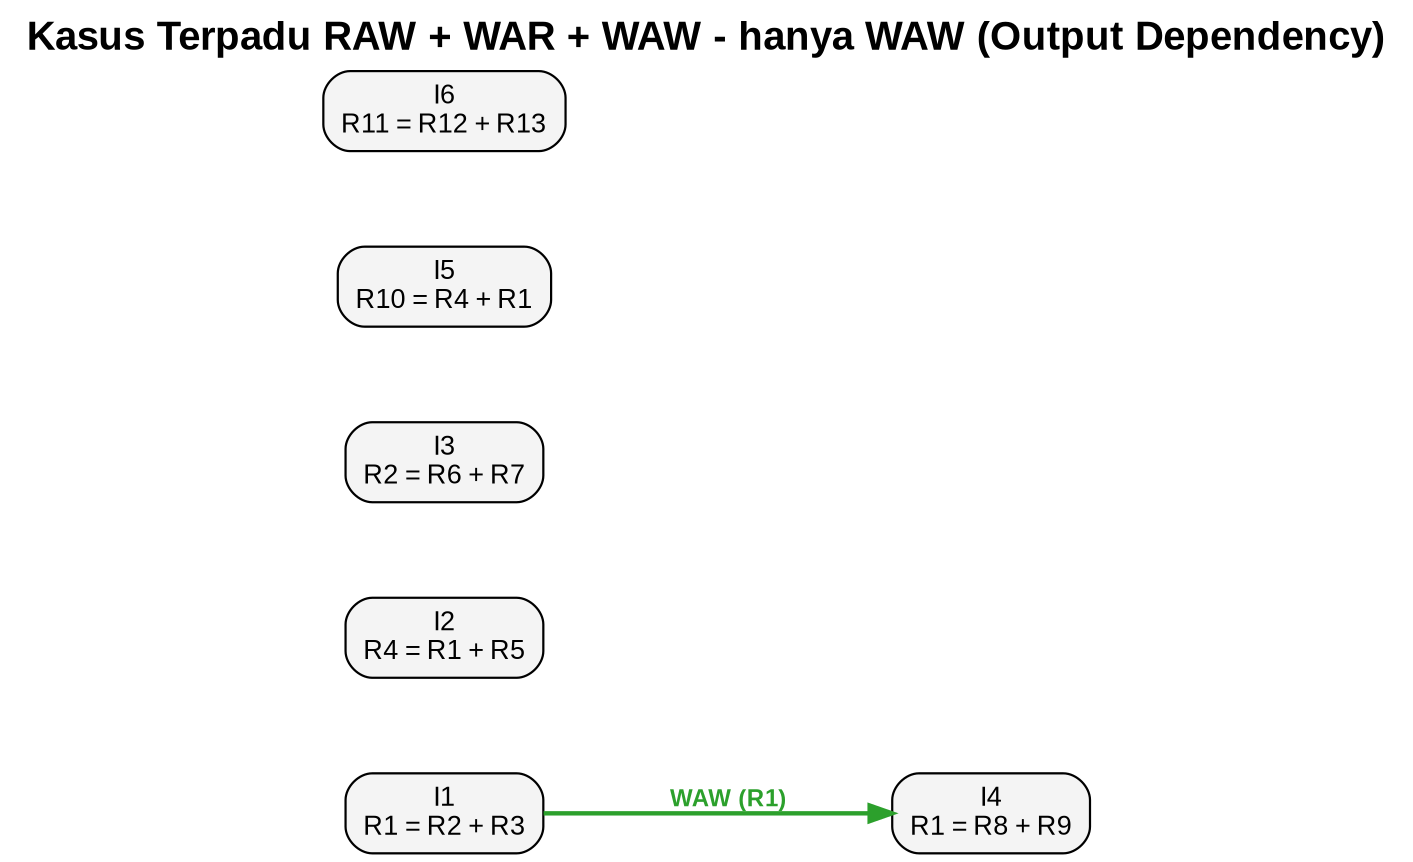

GABUNGAN


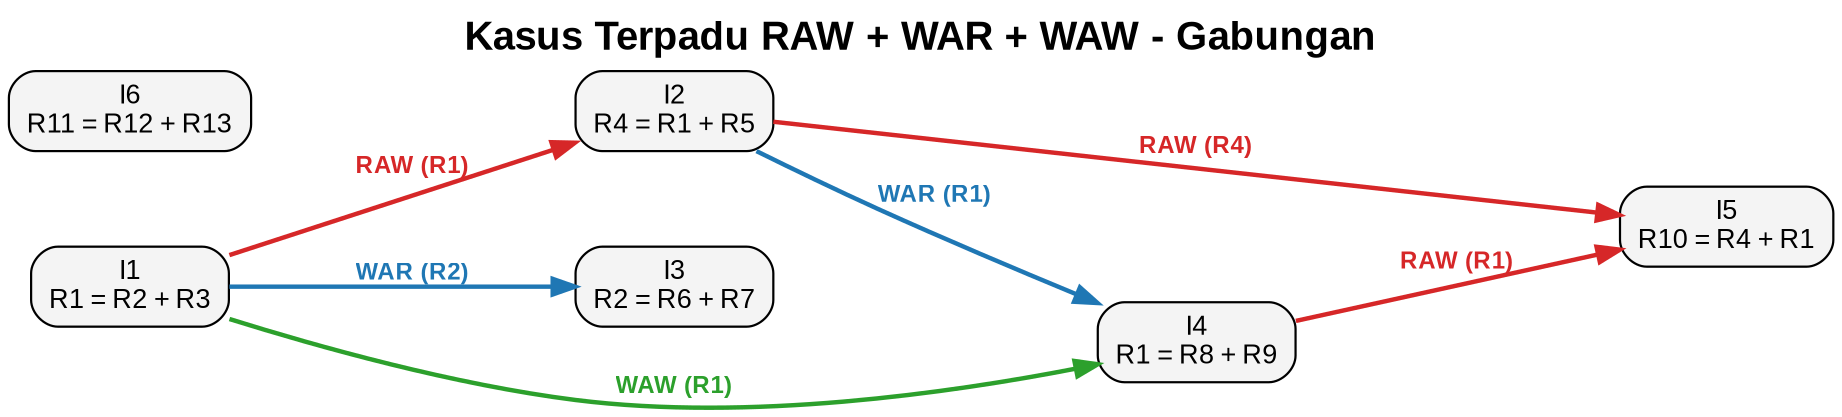

In [4]:
# Tampilkan semua graph di notebook
from IPython.display import Image, display
for k in ["RAW", "WAR", "WAW", "GABUNGAN"]:
    print(k); display(Image(paths_case[k]))
